In [1]:
import numpy as np 
import pandas as pd 
import scanpy as sc 
import matplotlib.pyplot as plt
import muon as mu 
import os 
import json

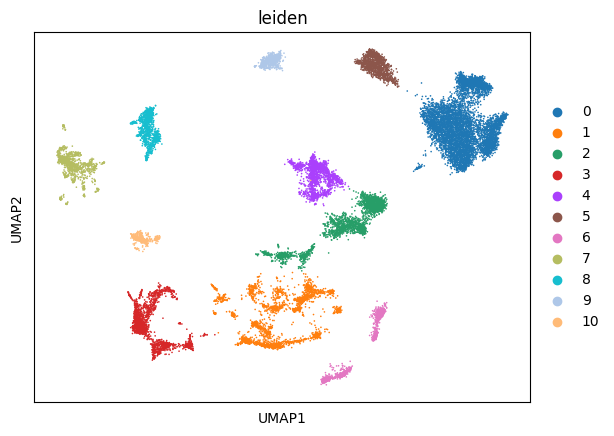

In [2]:
scdata = sc.read_h5ad('/home/rsun@ZHANGroup.local/sly_data/grn_momics/multi_rna_raw.h5ad')
sc.pl.umap(scdata, color = 'leiden')

In [16]:
os.makedirs('data', exist_ok=True)

## cydata

In [2]:
mdata = mu.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/CY/CYHM/filtered_feature_bc_matrix.h5')

atac = mdata['atac']

with open('/home/rsun@ZHANGroup.local/sly_data/coordinate_transfer/map_dic/cy_map.json', 'r') as f:
    tmp_map_dic = json.load(f) 

peaks = list(tmp_map_dic.keys())
for i, ele in enumerate(peaks):
    a,b,c = ele.split('_')
    peaks[i] = a + ':' + b + '-' + c
print(atac.shape[1], len(peaks)) 

map_dic = {}
for ele in tmp_map_dic:
    a,b,c = ele.split('_')
    key  = a + ':' + b + '-' + c
    map_dic[key] = tmp_map_dic[ele]
atac = atac[:,peaks]
atac.var.loc[:,'m_peaks'] = atac.var.loc[:,'gene_ids'].map(map_dic)
atac.var.index = atac.var.loc[:,'m_peaks'].values

mdata = mu.MuData({'rna': mdata['rna'], 'atac': atac})
mdata.write('cyhm_m.h5mu')

Added `interval` annotation for features from /home/rsun@ZHANGroup.local/sly_data/data/CY/CYHM/filtered_feature_bc_matrix.h5


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packa

Added peak annotation from /home/rsun@ZHANGroup.local/sly_data/data/CY/CYHM/atac_peak_annotation.tsv to .uns['atac']['peak_annotation']
Added gene names to peak annotation in .uns['atac']['peak_annotation']
Located fragments file: /home/rsun@ZHANGroup.local/sly_data/data/CY/CYHM/atac_fragments.tsv.gz
index `/home/rsun@ZHANGroup.local/sly_data/data/CY/CYHM/atac_fragments.tsv.gz.tbi` not found
176965 130706


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  self.obj[key] = value
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will

## qfdata

In [29]:
mdata = mu.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/QF/QFHM/outs/filtered_feature_bc_matrix.h5')

atac = mdata['atac']

with open('/home/rsun@ZHANGroup.local/sly_data/coordinate_transfer/map_dic/qf_map.json', 'r') as f:
    tmp_map_dic = json.load(f) 

peaks = list(tmp_map_dic.keys())
for i, ele in enumerate(peaks):
    a,b,c = ele.split('_')
    peaks[i] = a + ':' + b + '-' + c
print(atac.shape[1], len(peaks)) 

map_dic = {}
for ele in tmp_map_dic:
    a,b,c = ele.split('_')
    key  = a + ':' + b + '-' + c
    map_dic[key] = tmp_map_dic[ele]
atac = atac[:,peaks]
atac.var.loc[:,'m_peaks'] = atac.var.loc[:,'gene_ids'].map(map_dic)
atac.var.index = atac.var.loc[:,'m_peaks'].values

mdata = mu.MuData({'rna': mdata['rna'], 'atac': atac})
mdata.write('qfhm_m.h5mu')

Added `interval` annotation for features from /home/rsun@ZHANGroup.local/sly_data/data/QF/QFHM/outs/filtered_feature_bc_matrix.h5


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packa

Added peak annotation from /home/rsun@ZHANGroup.local/sly_data/data/QF/QFHM/outs/atac_peak_annotation.tsv to .uns['atac']['peak_annotation']
Added gene names to peak annotation in .uns['atac']['peak_annotation']
Located fragments file: /home/rsun@ZHANGroup.local/sly_data/data/QF/QFHM/outs/atac_fragments.tsv.gz


[W::hts_idx_load3] The index file is older than the data file: /home/rsun@ZHANGroup.local/sly_data/data/QF/QFHM/outs/atac_fragments.tsv.gz.tbi


111544 84728


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  self.obj[key] = value
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will

## jtdata

In [31]:
mdata = mu.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/JT/JTHM/filtered_feature_bc_matrix.h5')

atac = mdata['atac']

with open('/home/rsun@ZHANGroup.local/sly_data/coordinate_transfer/map_dic/jt_map.json', 'r') as f:
    tmp_map_dic = json.load(f) 

peaks = list(tmp_map_dic.keys())
for i, ele in enumerate(peaks):
    a,b,c = ele.split('_')
    peaks[i] = a + ':' + b + '-' + c
print(atac.shape[1], len(peaks)) 

map_dic = {}
for ele in tmp_map_dic:
    a,b,c = ele.split('_')
    key  = a + ':' + b + '-' + c
    map_dic[key] = tmp_map_dic[ele]
atac = atac[:,peaks]
atac.var.loc[:,'m_peaks'] = atac.var.loc[:,'gene_ids'].map(map_dic)
atac.var.index = atac.var.loc[:,'m_peaks'].values

mdata = mu.MuData({'rna': mdata['rna'], 'atac': atac})
mdata.write('jthm_m.h5mu')

Added `interval` annotation for features from /home/rsun@ZHANGroup.local/sly_data/data/JT/JTHM/filtered_feature_bc_matrix.h5


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packa

Added peak annotation from /home/rsun@ZHANGroup.local/sly_data/data/JT/JTHM/atac_peak_annotation.tsv to .uns['atac']['peak_annotation']
Added gene names to peak annotation in .uns['atac']['peak_annotation']
Located fragments file: /home/rsun@ZHANGroup.local/sly_data/data/JT/JTHM/atac_fragments.tsv.gz
index `/home/rsun@ZHANGroup.local/sly_data/data/JT/JTHM/atac_fragments.tsv.gz.tbi` not found
208463 154975


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  self.obj[key] = value
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will

## tdata

In [ ]:
mdata = mu.read_10x_h5('/home/rsun@ZHANGroup.local/sly_data/data/T/THM/filtered_feature_bc_matrix.h5')

atac = mdata['atac']

with open('/home/rsun@ZHANGroup.local/sly_data/coordinate_transfer/map_dic/t_map.json', 'r') as f:
    tmp_map_dic = json.load(f) 

peaks = list(tmp_map_dic.keys())
for i, ele in enumerate(peaks):
    a,b,c = ele.split('_')
    peaks[i] = a + ':' + b + '-' + c
print(atac.shape[1], len(peaks)) 

map_dic = {}
for ele in tmp_map_dic:
    a,b,c = ele.split('_')
    key  = a + ':' + b + '-' + c
    map_dic[key] = tmp_map_dic[ele]
atac = atac[:,peaks]
atac.var.loc[:,'m_peaks'] = atac.var.loc[:,'gene_ids'].map(map_dic)
atac.var.index = atac.var.loc[:,'m_peaks'].values

mdata = mu.MuData({'rna': mdata['rna'], 'atac': atac})
mdata.write('thm_m.h5mu')

/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Added `interval` annotation for features from /home/rsun@ZHANGroup.local/sly_data/data/T/THM/filtered_feature_bc_matrix.h5


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:915: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  warnings.warn(
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-package

Added peak annotation from /home/rsun@ZHANGroup.local/sly_data/data/T/THM/atac_peak_annotation.tsv to .uns['atac']['peak_annotation']
Added gene names to peak annotation in .uns['atac']['peak_annotation']
Located fragments file: /home/rsun@ZHANGroup.local/sly_data/data/T/THM/atac_fragments.tsv.gz
index `/home/rsun@ZHANGroup.local/sly_data/data/T/THM/atac_fragments.tsv.gz.tbi` not found
176032 139412


/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/pandas/core/indexing.py:1857: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  self.obj[key] = value
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/_core/mudata.py:915: UserWarning: var_names are not unique. To make them unique, call `.var_names_make_unique`.
  warnings.warn(
/home/rsun@ZHANGroup.local/anaconda3/envs/snapatac/lib/python3.10/site-packages/mudata/